## Analyzing a player's dismissals patterns, strengths and weaknesses

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats
import numpy as np

In [2]:
# Define the team
team = "India"  # Change to "Pakistan" as needed

# Map team names to their respective file paths
file_paths = {
    "India": 'data/Dismissal Types CT17 Squad ODI Career - IND.csv',
    "Pakistan": 'data/Dismissal Types CT17 Squad ODI Career - PAK.csv'
}

# Check if the selected team is valid and load the data
if team not in file_paths:
    raise ValueError(f"Error: Data for team '{team}' is not available.")

# Load the CSV file into a DataFrame
player_dismissal_file = file_paths[team]
data = pd.read_csv(player_dismissal_file)

# Display the first few rows of the DataFrame
print(data.head())


    Player Name  Player ID      Bowler Type       Span  Dis  bwd  c fie  c wk  \
0  Rohit Sharma          1   right-arm pace  2007-2023  123   19     60    31   
1           NaN          1   right-arm spin  2007-2023   40   11     18     4   
2           NaN          1    left-arm pace  2008-2023   33    6     20     4   
3           NaN          1    left-arm spin  2008-2023    9    3      4     0   
4           NaN          1  mixture/unknown  2008-2019   13    0      0     0   

   st  lbw  hw  ro  oth  no    Ave  0s    BF  Runs  
0   0   13   0   0    0   0  35.21   9  4811  4331  
1   2    5   0   0    0   0  51.45   1  2195  2058  
2   0    3   0   0    0   0  28.06   4  1024   926  
3   1    1   0   0    0   0  50.44   1   521   454  
4   0    0   0  13    0   0  39.92   1  3093  2940  


In [3]:
# Display the summary of the DataFrame
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 18 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Player Name  10 non-null     object 
 1   Player ID    51 non-null     int64  
 2   Bowler Type  51 non-null     object 
 3   Span         51 non-null     object 
 4   Dis          51 non-null     int64  
 5   bwd          51 non-null     int64  
 6   c fie        51 non-null     int64  
 7   c wk         51 non-null     int64  
 8   st           51 non-null     int64  
 9   lbw          51 non-null     int64  
 10  hw           51 non-null     int64  
 11  ro           51 non-null     int64  
 12  oth          51 non-null     int64  
 13  no           51 non-null     int64  
 14  Ave          51 non-null     float64
 15  0s           51 non-null     int64  
 16  BF           51 non-null     int64  
 17  Runs         51 non-null     int64  
dtypes: float64(1), int64(14), object(3)
memory usage: 7.

## Extracting Player's Statistics

In [4]:
# Define the player name
player_name = "Virat Kohli"  # Change this as needed eg "Kehdar Jadhav", "Babar Azam"

# Check if the player name exists in the DataFrame
if player_name in data['Player Name'].values:
    # Filter the DataFrame to find the Player ID based on Player Name
    player_id = data.loc[data['Player Name'] == player_name, 'Player ID']

    # Display the Player ID
    print(f"Player ID of {player_name}: {player_id.values[0]}\n")

    # Filter the data for Player
    player_data = data[data['Player ID'] == player_id.values[0]]

    # Display the data for Player
    print(player_data)
else:
    # Output an error message
    print(f"Error: Player '{player_name}' not found in the DataFrame.")
    # Raise an exception to stop further execution
    raise ValueError(f"Player '{player_name}' not found in the DataFrame.")


Player ID of Virat Kohli: 3

    Player Name  Player ID      Bowler Type       Span  Dis  bwd  c fie  c wk  \
10  Virat Kohli          3   right-arm pace  2008-2023  120   14     62    37   
11          NaN          3   right-arm spin  2009-2023   47   10     22     5   
12          NaN          3    left-arm pace  2008-2023   34    5     18     9   
13          NaN          3    left-arm spin  2009-2023   23    5     14     1   
14          NaN          3  mixture/unknown  2008-2018   12    0      0     0   

    st  lbw  hw  ro  oth  no    Ave  0s    BF  Runs  
10   0    7   0   0    0   0  44.91   9  5905  5390  
11   3    6   1   0    0   0  51.55   0  2619  2423  
12   0    2   0   0    0   0  29.44   4  1204  1001  
13   2    1   0   0    0   0  34.30   1  1011   789  
14   0    0   0  12    0   0  46.00   2  4058  4245  


# Analysis of Dismissal Types for the player

In [5]:
#Drop rows where 'Bowler Type' is 'mixture/unknown'
player_data_filtered = player_data[player_data['Bowler Type'] != 'mixture/unknown']

In [6]:
# List of dismissal types
dismissal_types = ['bwd', 'c fie', 'c wk', 'st', 'lbw', 'hw', 'ro']

# Aggregate dismissal counts
dismissal_counts = player_data[dismissal_types].sum()

# Display the aggregated dismissal counts
print(dismissal_counts)

bwd       34
c fie    116
c wk      52
st         5
lbw       16
hw         1
ro        12
dtype: int64


A pie chart visualization will display the different ways the player has been dismissed, showing the proportion of each dismissal type. This chart provides a clear and concise view of the frequency of each dismissal type

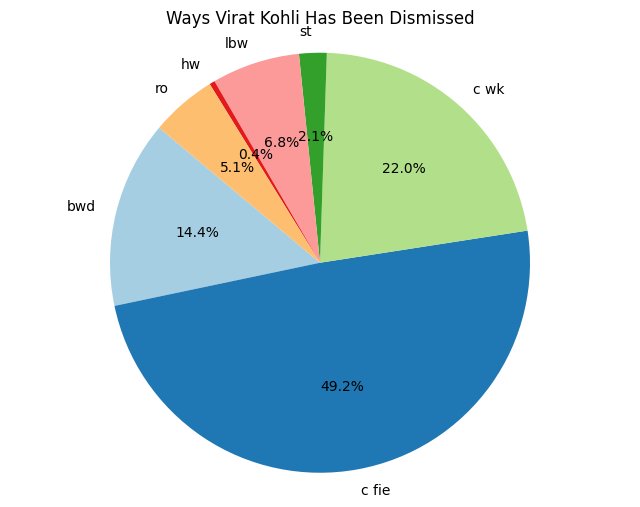

In [7]:
# pie chart
plt.figure(figsize=(8, 6))
plt.pie(dismissal_counts, labels=dismissal_counts.index, autopct='%1.1f%%', colors=plt.cm.Paired(range(len(dismissal_counts))), startangle=140)
plt.title(f'Ways {player_name} Has Been Dismissed')
plt.axis('equal')  # Equal aspect ratio ensures that pie is drawn as a circle.
plt.show()

Dismissals of the player against diffrent bowler types

In [8]:
# List of dismissal types
dismissal_types = ['bwd', 'c fie', 'c wk', 'st', 'lbw',]

# Aggregate dismissal counts by bowler type
dismissals_by_bowler_type = player_data_filtered.groupby('Bowler Type')[dismissal_types].sum().reset_index()

# Display the aggregated dismissal counts
print(dismissals_by_bowler_type)

      Bowler Type  bwd  c fie  c wk  st  lbw
0   left-arm pace    5     18     9   0    2
1   left-arm spin    5     14     1   2    1
2  right-arm pace   14     62    37   0    7
3  right-arm spin   10     22     5   3    6


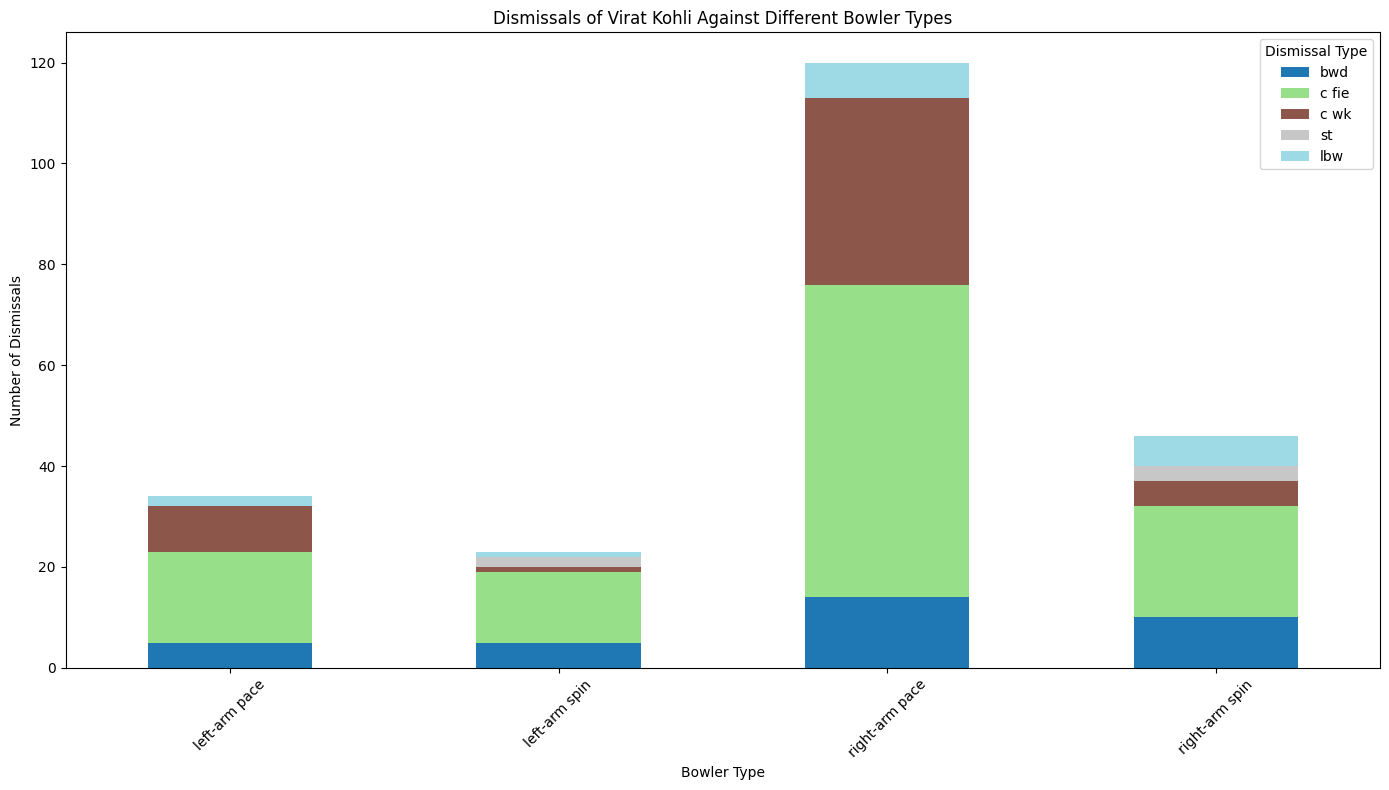

In [9]:
# Plot a stacked bar plot
dismissals_by_bowler_type.set_index('Bowler Type')[dismissal_types].plot(kind='bar', stacked=True, figsize=(14, 8), colormap='tab20')
plt.title(f'Dismissals of {player_name} Against Different Bowler Types')
plt.xlabel('Bowler Type')
plt.ylabel('Number of Dismissals')
plt.legend(title='Dismissal Type')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [10]:
# dismissals_by_bowler_type.head
dismissals_by_bowler_type.columns

Index(['Bowler Type', 'bwd', 'c fie', 'c wk', 'st', 'lbw'], dtype='object')

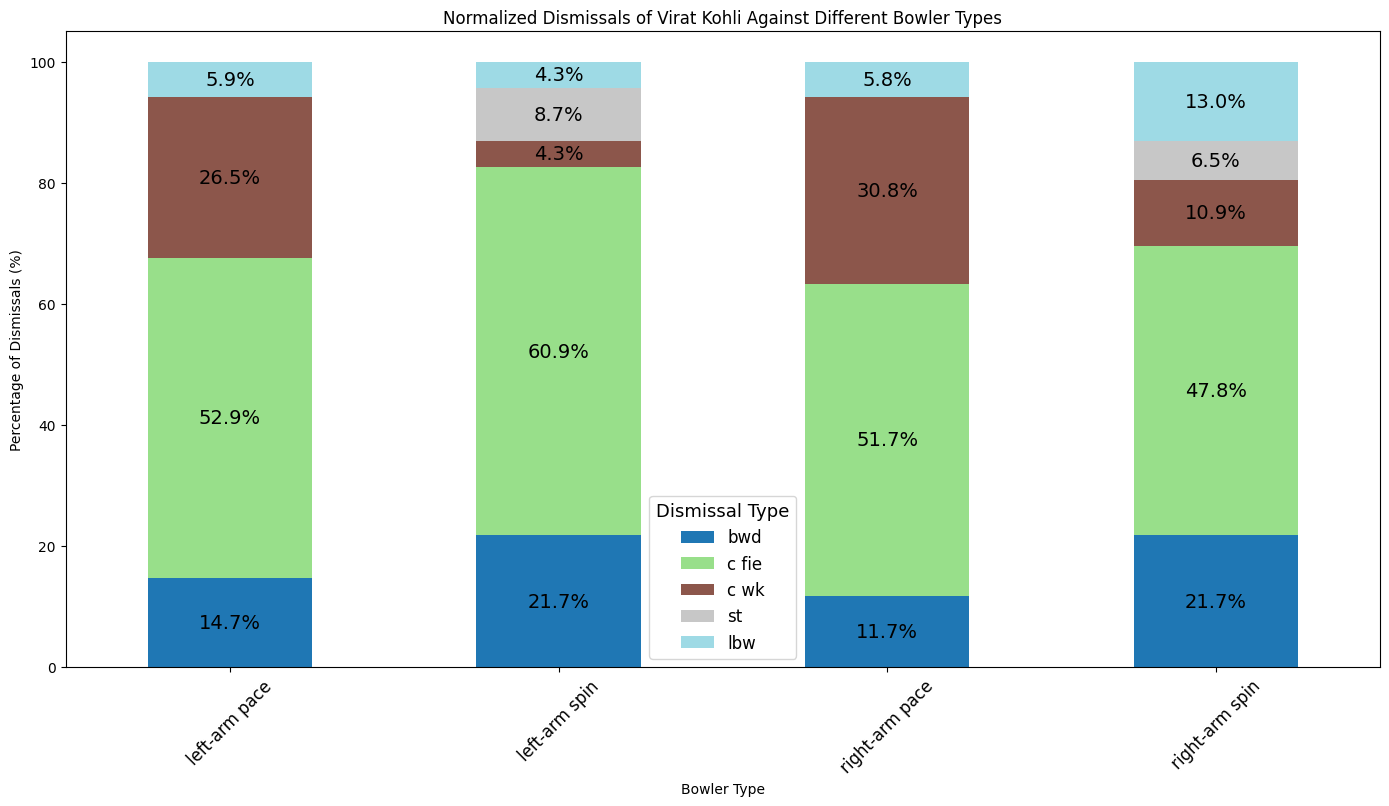

In [11]:
# Calculate total dismissals for each bowler type
dismissals_by_bowler_type['Total Dismissals'] = dismissals_by_bowler_type[dismissal_types].sum(axis=1)

# Normalize each dismissal type by the total dismissals for that bowler type
for dismissal_type in dismissal_types:
    dismissals_by_bowler_type[dismissal_type] = (dismissals_by_bowler_type[dismissal_type] / dismissals_by_bowler_type['Total Dismissals']) * 100

# Drop the total dismissals column as it's no longer needed
dismissals_by_bowler_type.drop(columns='Total Dismissals', inplace=True)

# Plot the normalized stacked bar plot
ax = dismissals_by_bowler_type.set_index('Bowler Type')[dismissal_types].plot(kind='bar', stacked=True, figsize=(14, 8), colormap='tab20')

# Add labels and title
plt.title(f'Normalized Dismissals of {player_name} Against Different Bowler Types')
plt.xlabel('Bowler Type')
plt.ylabel('Percentage of Dismissals (%)')
plt.xticks(rotation=45)
plt.tight_layout()

# Add percentage labels within the bars
for i in range(dismissals_by_bowler_type.shape[0]):
    bottom = 0
    for j, col in enumerate(dismissal_types):
        value = dismissals_by_bowler_type.iloc[i][col]
        if value > 0:
            ax.text(i, bottom + value / 2, f'{value:.1f}%', ha='center', va='center', color='black', fontsize=14)
        bottom += value

ax.legend(title='Dismissal Type', title_fontsize=13, fontsize=12)
ax.tick_params(axis='x', labelsize=12)

# Show the plot
plt.show()


Normalizing the dismissals by each bowler against the player with the balls faced

In [12]:
# Aggregate total dismissals and balls faced by bowler type
dismissals_by_bowler_type = player_data_filtered.groupby('Bowler Type')['Dis'].sum().reset_index()
balls_faced_by_bowler_type = player_data_filtered.groupby('Bowler Type')['BF'].sum().reset_index()

# Merge the two DataFrames
dismissals_balls = pd.merge(dismissals_by_bowler_type, balls_faced_by_bowler_type, on='Bowler Type')

# Calculate dismissal rate per ball faced
dismissals_balls['Dismissal Rate'] = dismissals_balls['Dis'] / dismissals_balls['BF']

# Display the normalized dismissal rates
print(dismissals_balls)

      Bowler Type  Dis    BF  Dismissal Rate
0   left-arm pace   34  1204        0.028239
1   left-arm spin   23  1011        0.022750
2  right-arm pace  120  5905        0.020322
3  right-arm spin   47  2619        0.017946


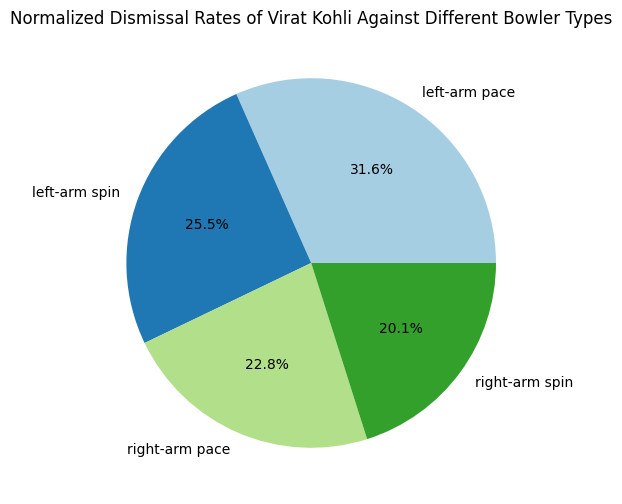

In [13]:
# Prepare data for pie plot
pie_data = dismissals_balls.set_index('Bowler Type')['Dismissal Rate']

# Plot a pie chart
plt.figure(figsize=(8, 6))
plt.pie(pie_data, labels=pie_data.index, autopct='%1.1f%%', colors=plt.cm.Paired(range(len(pie_data))))
plt.title(f'Normalized Dismissal Rates of {player_name} Against Different Bowler Types')
plt.show()

# Analysis of Runs Scored for the player

Extracting the Runs data of selected player

In [14]:
# Aggregate total runs scored against each bowler type
runs_by_bowler_type = player_data_filtered.groupby('Bowler Type')['Runs'].sum().reset_index()

# Display the aggregated data
print(runs_by_bowler_type)

      Bowler Type  Runs
0   left-arm pace  1001
1   left-arm spin   789
2  right-arm pace  5390
3  right-arm spin  2423


Bar plot of Runs Scored by the player against each Bowler Type

<Figure size 1200x600 with 0 Axes>

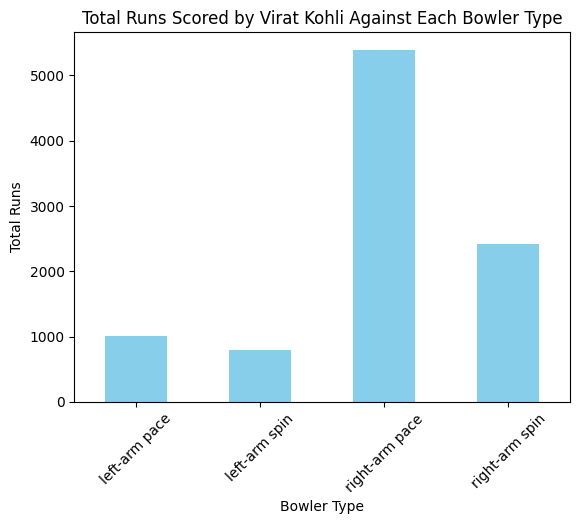

In [15]:
plt.figure(figsize=(12, 6))
runs_by_bowler_type.plot(kind='bar', x='Bowler Type', y='Runs', color='skyblue', legend=False)
plt.title(f'Total Runs Scored by {player_name} Against Each Bowler Type')
plt.xlabel('Bowler Type')
plt.ylabel('Total Runs')
plt.xticks(rotation=45)
plt.show()

Plot both runs scored and balls faced by the player for each bowler type

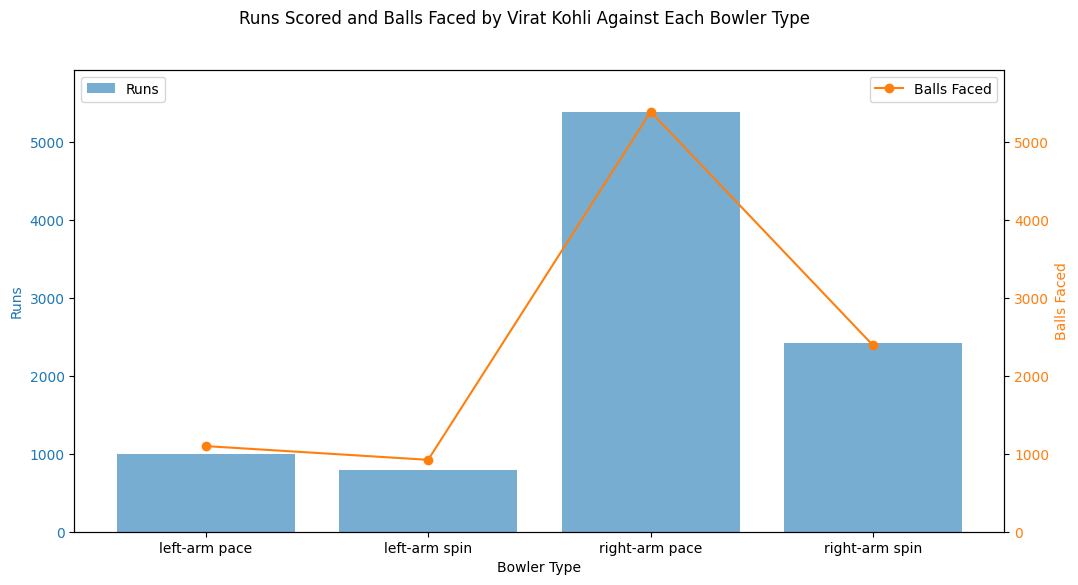

In [16]:
import matplotlib.pyplot as plt

# Aggregate total runs and balls faced against each bowler type
runs_balls_by_bowler_type = player_data_filtered.groupby('Bowler Type').agg({'Runs': 'sum', 'BF': 'sum'}).reset_index()

# Determine the common limit based on the maximum value of runs and balls faced
max_runs = runs_balls_by_bowler_type['Runs'].max()
max_balls_faced = runs_balls_by_bowler_type['BF'].max()

# Calculate scaling factor to normalize the secondary axis to the primary axis range
scaling_factor = max_runs / max_balls_faced

# Create a dual-axis plot
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot Runs on the primary y-axis
color = 'tab:blue'
ax1.set_xlabel('Bowler Type')
ax1.set_ylabel('Runs', color=color)
ax1.bar(runs_balls_by_bowler_type['Bowler Type'], runs_balls_by_bowler_type['Runs'], color=color, alpha=0.6, label='Runs')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_ylim(0, max_runs * 1.1)  # Extend limit a bit for better visibility

# Create a secondary y-axis for Balls Faced
ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel('Balls Faced', color=color)
# Normalize the Balls Faced data to align with the Runs data range
ax2.plot(runs_balls_by_bowler_type['Bowler Type'], runs_balls_by_bowler_type['BF'] * scaling_factor, color=color, marker='o', label='Balls Faced')
ax2.tick_params(axis='y', labelcolor=color)
ax2.set_ylim(0, max_runs * 1.1)  # Use the same range as the primary y-axis

# Add titles and legends
fig.suptitle(f'Runs Scored and Balls Faced by {player_name} Against Each Bowler Type')
ax1.legend(loc='upper left')
ax2.legend(loc='upper right')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45)

plt.show()


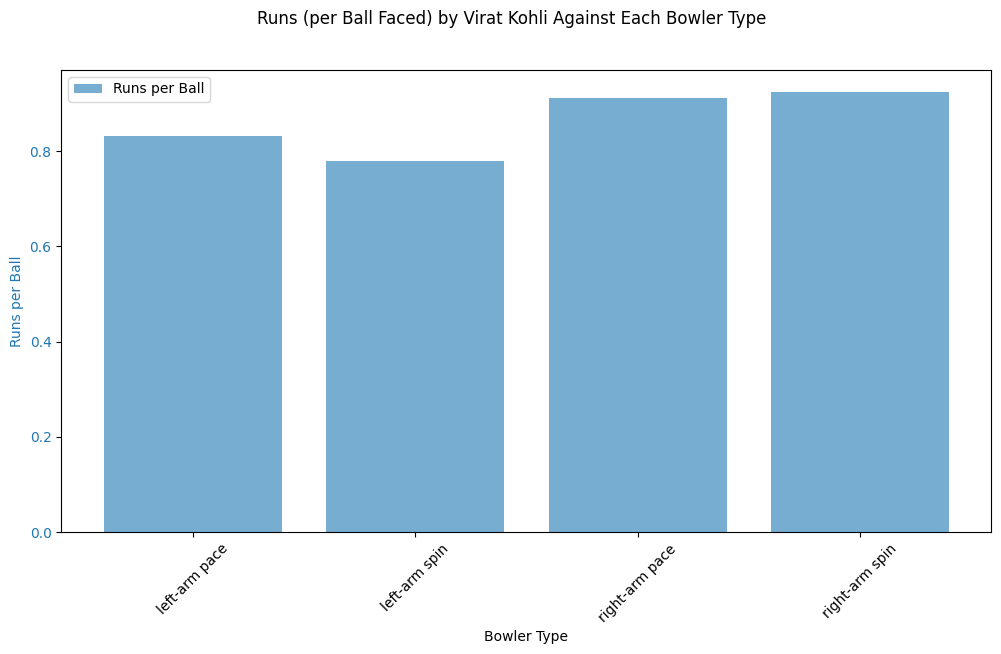

In [17]:
# Normalize runs against balls faced by calculating runs per ball
runs_balls_by_bowler_type['Runs per Ball'] = runs_balls_by_bowler_type['Runs'] / runs_balls_by_bowler_type['BF']

# Plot the normalized data
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot normalized runs per ball
color = 'tab:blue'
ax1.set_xlabel('Bowler Type')
ax1.set_ylabel('Runs per Ball', color=color)
ax1.bar(runs_balls_by_bowler_type['Bowler Type'], runs_balls_by_bowler_type['Runs per Ball'], color=color, alpha=0.6, label='Runs per Ball')
ax1.tick_params(axis='y', labelcolor=color)

# Add titles and legend
fig.suptitle(f'Runs (per Ball Faced) by {player_name} Against Each Bowler Type')
ax1.legend(loc='upper left')

# Rotate x-axis labels for better readability
plt.xticks(rotation=45)

plt.show()

Plot of average runs scored by the player against each bowler type

In [18]:
# Average runs scored against each bowler type
avg_runs_by_bowler_type = player_data_filtered.groupby('Bowler Type')['Ave'].sum().reset_index()

# Display the aggregated data
print(avg_runs_by_bowler_type)

      Bowler Type    Ave
0   left-arm pace  29.44
1   left-arm spin  34.30
2  right-arm pace  44.91
3  right-arm spin  51.55


Bar plot of Average Runs Scored by the player against each Bowler Type

<Figure size 1200x600 with 0 Axes>

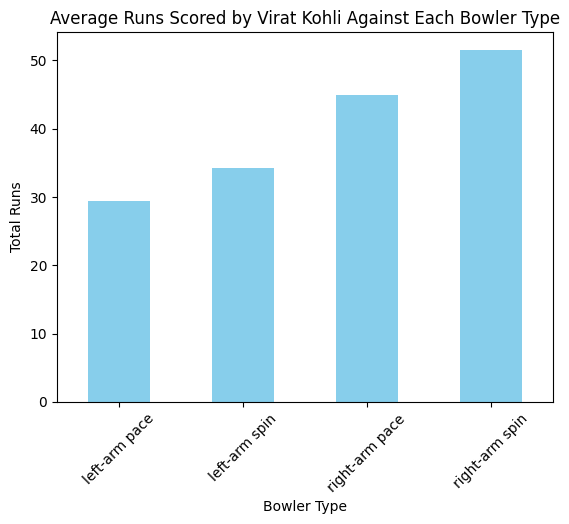

In [19]:
plt.figure(figsize=(12, 6))
avg_runs_by_bowler_type.plot(kind='bar', x='Bowler Type', y='Ave', color='skyblue', legend=False)
plt.title(f'Average Runs Scored by {player_name} Against Each Bowler Type')
plt.xlabel('Bowler Type')
plt.ylabel('Total Runs')
plt.xticks(rotation=45)
plt.show()

Pie plot of avg runs for % visualization

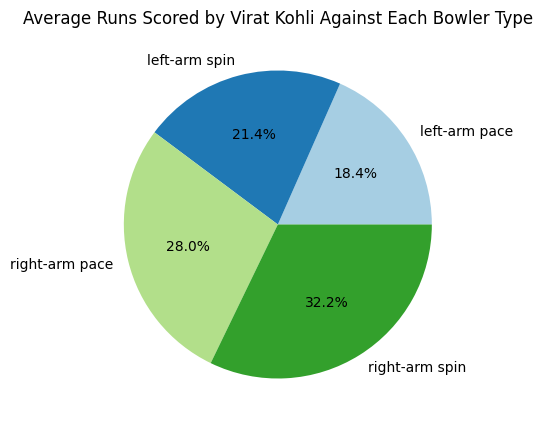

In [20]:
plt.figure(figsize=(5, 5))
avg_runs_by_bowler_type.set_index('Bowler Type')['Ave'].plot(kind='pie', autopct='%1.1f%%', colors=plt.cm.Paired(range(len(avg_runs_by_bowler_type))), legend=False)
plt.title(f'Average Runs Scored by {player_name} Against Each Bowler Type')
plt.ylabel('')
plt.show()